# Forecast contracts

**A forecast for the wrong dates, or with two series swapped, can look perfectly plausible, so every forecast is checked against what was asked before it is scored.**

This chapter builds `timegym.contracts`, the agreement between TimeGym and a model. `ForecastTask` is what the model may see: the history and the dates to forecast. `Forecast` is what it returns: a point forecast, and optionally quantiles and sample paths. `Forecast.validate` runs the output checks: right dates, every series in order, right shape, finite values, quantiles in order. `Reference` is the form an answer key takes, and `Case` bundles a task with what only the evaluator keeps.

Below, a correct forecast passes the checks and five common mistakes fail them, each with a plain message. Then the answer key's own forecast shows what sample paths say that quantiles can't, and a curve you know becomes an answer key.

**Development notebook.** The collapsed cells are the source of `timegym/contracts.py`; expand them to edit, then follow the [build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp contracts

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110, 'font.size': 11,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})
pd.set_option('display.max_colwidth', None)
BLUE = '#0000CC'

## Build the contracts

First the checks on labels, then the task, the forecast and its output checks, the answer key in two forms, and the case.

### Imports and defaults

Quantile forecasts default to the 10%, 50% and 90% levels.

In [3]:
#| export contracts
from __future__ import annotations
from timegym._internal import positive_int, nonnegative_int, _real_array, _has_complex_values

from dataclasses import dataclass, field
from typing import Any, Callable

import numpy as np
import pandas as pd
from scipy.stats import norm

DEFAULT_LEVELS = (0.1, 0.5, 0.9)
MANIFEST_SCHEMA_VERSION = 1


### Labels a check can trust

Dates and series names must be real labels: no missing or infinite values, and no series name twice. These helpers find the problem so that a message can name it.

In [4]:
#| export contracts
def _index_value_problem(index: pd.Index) -> str | None:
    """Identify missing or infinite labels without coercing time indexes."""
    if isinstance(index, pd.MultiIndex):
        if any(np.any(codes < 0) for codes in index.codes):
            return "missing"
        for level in index.levels:
            problem = _index_value_problem(level)
            if problem is not None:
                return problem
    else:
        if index.hasnans:
            return "missing"
        for value in index:
            # Object indexes may contain tuples even when they are not a
            # MultiIndex. Inspect each component, including nested tuples.
            if isinstance(value, tuple):
                problem = _index_value_problem(pd.Index(value, tupleize_cols=False))
                if problem is not None:
                    return problem
            elif isinstance(value, (float, complex, np.floating, np.complexfloating)) and not np.isfinite(value):
                return "nonfinite"
    return None


def _target_labels(values, name="target names") -> tuple:
    """Normalize unique hashable labels, rejecting scalar strings and missing names."""
    if isinstance(values, (str, bytes)):
        raise ValueError(f"{name} must be a sequence of unique, nonmissing labels")
    try:
        names = tuple(values)
        if not names or len(set(names)) != len(names):
            raise ValueError
        index = pd.Index(names, tupleize_cols=False)
        if _index_value_problem(index) is not None:
            raise ValueError
    except (TypeError, ValueError):
        raise ValueError(f"{name} must be a sequence of unique, nonmissing, finite, hashable labels") from None
    return names

### How far off are the dates?

A forecast for the wrong dates fails before it is scored. When its dates are the requested ones moved by whole steps, `_index_shift` counts the steps, so the scorecard can say "Wrong dates: shifted 1 step late" instead of only that the dates don't match.

In [5]:
#| export contracts
def _index_shift(index, future_index):
    """Return ``k`` when ``index`` is the requested ``future_index`` moved ``k`` steps.

    Negative ``k`` means the labels start early (``-1``: at the last observed
    step), positive means late. Returns ``None`` when the labels are not a
    whole-step shift of the requested ones, for example a truncated horizon.
    Steps come from the requested index: its frequency for time indexes, its
    constant spacing for numeric ones.
    """
    if not isinstance(index, pd.Index) or len(index) != len(future_index) or len(index) == 0:
        return None
    if index.equals(future_index):
        return 0
    if isinstance(future_index, (pd.DatetimeIndex, pd.TimedeltaIndex, pd.PeriodIndex)):
        frequency = future_index.freq
        if frequency is None and len(future_index) >= 3:
            frequency = pd.infer_freq(future_index)
        if frequency is None:
            return None

        def moved(k):
            return future_index.shift(k, freq=frequency) if not isinstance(future_index, pd.PeriodIndex) else future_index + k
    elif pd.api.types.is_numeric_dtype(future_index.dtype) and len(future_index) >= 2:
        steps = np.diff(future_index.to_numpy())
        if not np.all(steps == steps[0]) or steps[0] == 0:
            return None

        def moved(k):
            return future_index + k * steps[0]
    else:
        return None
    for distance in range(1, 4 * len(future_index) + 1):
        for k in (-distance, distance):
            try:
                if index.equals(moved(k)):
                    return k
            except (TypeError, ValueError, OverflowError):
                return None
    return None


def _describe_shift(k):
    """Say in words how far forecast dates moved from the requested ones."""
    steps = f"{abs(k)} step{'s' if abs(k) != 1 else ''}"
    return f"shifted {steps} {'early' if k < 0 else 'late'}"

### What the model may see (`ForecastTask`)

A task holds the history (`context`, one column per series) and the dates to forecast (`future_index`), and nothing else. It refuses history with missing or infinite values, dates that are not unique and increasing, and dates to forecast that don't start after the history ends.

In [6]:
#| export contracts
@dataclass
class ForecastTask:
    """The information a forecaster may observe at a single forecast origin."""

    context: pd.DataFrame
    future_index: pd.Index

    def __post_init__(self) -> None:
        if not isinstance(self.context, pd.DataFrame):
            raise TypeError("context must be a pandas DataFrame")
        if self.context.empty or len(self.context.columns) == 0:
            raise ValueError("context must contain at least one row and target")
        _target_labels(self.context.columns, "context target names")
        for name, index in (("context", self.context.index), ("future", self.future_index)):
            if not isinstance(index, pd.Index):
                raise TypeError(f"{name} index must be a pandas Index")
            problem = _index_value_problem(index)
            if problem is not None:
                raise ValueError(f"{name} index must not contain {problem} labels")
            if len(index) == 0 or not index.is_unique or not index.is_monotonic_increasing:
                raise ValueError(f"{name} index must be nonempty, unique, and increasing")
        try:
            values = _real_array(self.context.to_numpy(), "context")
        except (TypeError, ValueError) as exc:
            raise ValueError("context values must be real numeric values") from exc
        if not np.isfinite(values).all():
            raise ValueError("context values must be finite")
        try:
            follows_context = self.future_index[0] > self.context.index[-1]
        except TypeError as exc:
            raise ValueError("context and future indexes must be comparable") from exc
        if not follows_context:
            raise ValueError("future index must begin after the context ends")

    @property
    def target_names(self) -> tuple:
        """The context's target column names, in order."""
        return tuple(self.context.columns)

### What the model returns, and the output checks (`Forecast`)

A forecast holds the dates it is for (`index`) and up to three kinds of prediction: `point`, the predictive mean, with one row per date and one column per series; `quantiles` at the probability `levels`; and `samples`, whole future paths. `target_names` names the series, and its default, None, means the task's series in order.

Building a `Forecast` checks nothing, so that a broken output can still be examined. `validate(task)` runs the output checks and returns one finding, a code and a message, for each problem, or an empty list when there is none.

In [7]:
#| export contracts
@dataclass
class Forecast:
    """A model output, including malformed outputs that need diagnosis.

    Construction intentionally does not validate or repair data. Call
    ``validate`` to obtain stable diagnostic codes before scoring it.
    A point forecast denotes a predictive mean, not an arbitrary quantile.
    ``target_names=None`` means the task's series, in order (``("y",)``
    when validated without a task).
    """

    index: pd.Index
    point: np.ndarray | None = None
    quantiles: np.ndarray | None = None
    levels: tuple = ()
    samples: np.ndarray | None = None
    target_names: tuple | None = None

    def validate(self, task: ForecastTask | None = None) -> list[dict[str, str]]:
        """Return one ``{"code", "message"}`` finding per contract violation.

        An empty list means the output meets its contract. With a ``task``, the
        index and target names must also match the task's future index and
        targets. Each code is reported as the diagnostic ``contract_<code>``.
        """
        findings: list[dict[str, str]] = []

        def add(code: str, message: str) -> None:
            findings.append({"code": code, "message": message})

        if not isinstance(self.index, pd.Index):
            add("index_type", "Forecast index must be a pandas Index.")
            horizon = len(task.future_index) if task is not None else None
        else:
            horizon = len(self.index)
            problem = _index_value_problem(self.index)
            if problem is not None:
                add("index_" + problem, f"Forecast index contains {problem} labels.")
            if horizon == 0:
                add("index_empty", "Forecast index must not be empty.")
            if not self.index.is_unique:
                add("index_duplicate", "Forecast index contains duplicate labels.")
            if not self.index.is_monotonic_increasing:
                add("index_order", "Forecast index is not increasing.")
            if task is not None and not self.index.equals(task.future_index):
                add("index_mismatch", "Forecast index does not match the requested future index.")
        declared = self.target_names
        if declared is None:
            declared = task.target_names if task is not None else ("y",)
        try:
            names = _target_labels(declared)
        except (TypeError, ValueError):
            names = task.target_names if task is not None else ()
            add("target_names", "Forecast target names must be a sequence of unique, nonmissing, finite, hashable labels.")
        if task is not None and names != task.target_names:
            add("target_mismatch", "Forecast targets or their order do not match the task.")
        dimensions = len(names)

        try:
            levels = _real_array(self.levels, "levels")
        except (TypeError, ValueError):
            levels = np.array([np.nan])
        valid_levels = (
            levels.ndim == 1
            and np.isfinite(levels).all()
            and ((levels > 0) & (levels < 1)).all()
        )
        if not valid_levels:
            add("invalid_levels", "Quantile levels must be finite real numbers strictly between zero and one.")
        elif len(levels):
            if len(np.unique(levels)) != len(levels):
                add("duplicate_levels", "Quantile levels contain duplicates.")
            if np.any(np.diff(levels) < 0):
                add("nonmonotonic_levels", "Quantile levels must be in increasing order.")
        if self.quantiles is not None and levels.size == 0:
            add("invalid_levels", "Quantile predictions require explicit probability levels.")
        if self.quantiles is None and levels.size != 0:
            add("missing_quantiles", "Quantile levels were supplied without quantile predictions.")

        if self.point is None and self.quantiles is None and self.samples is None:
            add("missing_prediction", "Supply point predictions, quantiles, or predictive samples.")
        for label, raw in (("point", self.point), ("quantiles", self.quantiles), ("samples", self.samples)):
            if raw is None:
                continue
            shape_code = {"point": "point_shape", "quantiles": "quantile_shape", "samples": "sample_shape"}[label]
            try:
                values = np.asarray(raw)
                if _has_complex_values(values):
                    add(f"nonreal_{label}", f"Forecast {label} must contain real-valued numbers.")
                    continue
                values = np.asarray(values, dtype=float)
            except (TypeError, ValueError):
                add(f"nonfinite_{label}", f"Forecast {label} must contain finite numeric values.")
                continue
            if label == "point":
                shape_ok = values.ndim == 2 and values.shape == (horizon, dimensions)
                expected = "(horizon, targets)"
            elif label == "quantiles":
                shape_ok = values.ndim == 3 and values.shape == (horizon, dimensions, levels.size)
                expected = "(horizon, targets, levels)"
            else:
                shape_ok = values.ndim == 3 and values.shape[0] > 0 and values.shape[1:] == (horizon, dimensions)
                expected = "(samples > 0, horizon, targets)"
            if not shape_ok:
                add(shape_code, f"Forecast {label} has shape {values.shape}; expected {expected}.")
            finite_values = np.isfinite(values).all()
            if not finite_values:
                add(f"nonfinite_{label}", f"Forecast {label} contains nonfinite values.")
            if label == "quantiles" and shape_ok and finite_values and valid_levels and np.all(np.diff(levels) > 0):
                if np.any(values[..., 1:] < values[..., :-1]):
                    add("quantile_crossing", "Predicted quantiles decrease as the probability level increases.")
        return findings

    def mean(self) -> np.ndarray:
        """Return the reported mean, or an empirical mean of predictive samples."""
        if self.point is not None:
            return _real_array(self.point, "point")
        if self.samples is not None:
            return _real_array(self.samples, "samples").mean(axis=0)
        raise ValueError("A predictive mean cannot be inferred from marginal quantiles alone")

### The answer key (`Reference`)

For the recipes of [01 · Synthetic data](01_synthetic_data.ipynb), the answer key is a Gaussian law: a mean and a variance for every date and series, and a covariance for how they all move together. `forecast()` turns it into the best possible `Forecast`, and `quantile` and `sample` give its quantiles and joint paths. `from_function` builds one from a curve you know. It knows the true settings, an advantage no fitted model has.

In [8]:
#| export contracts
@dataclass
class Reference:
    """A Gaussian conditional law given observed history and known parameters.

    This is an analytical diagnostic reference. Knowing generator parameters
    is an information advantage over an estimated forecasting model and must
    not be interpreted as attainable real-world performance.
    """

    mean: np.ndarray
    variance: np.ndarray
    covariance: np.ndarray
    index: pd.Index
    target_names: tuple = ("y",)
    kind: str = "analytic_conditional"
    functional: str = "mean"
    conditioning: dict[str, Any] = field(default_factory=dict)

    def __post_init__(self) -> None:
        self.validate()

    def validate(self) -> None:
        """Check current moments and labels using the construction tolerances."""
        self.mean = _real_array(self.mean, "Reference mean")
        self.variance = _real_array(self.variance, "Reference variance")
        self.covariance = _real_array(self.covariance, "Reference covariance")
        self.target_names = _target_labels(self.target_names, "Reference target names")
        if not isinstance(self.index, pd.Index) or len(self.index) == 0:
            raise ValueError("Reference index must be a nonempty pandas Index")
        problem = _index_value_problem(self.index)
        if problem is not None:
            raise ValueError(f"Reference index must not contain {problem} labels")
        if not self.index.is_unique or not self.index.is_monotonic_increasing:
            raise ValueError("Reference index must be unique and increasing")
        shape = (len(self.index), len(self.target_names))
        size = shape[0] * shape[1]
        if self.mean.shape != shape or self.variance.shape != shape:
            raise ValueError("Reference mean and variance must have shape (horizon, targets)")
        if self.covariance.shape != (size, size):
            raise ValueError("Reference covariance must have shape (horizon * targets, horizon * targets)")
        if not all(np.isfinite(a).all() for a in (self.mean, self.variance, self.covariance)):
            raise ValueError("Reference parameters must be finite")
        if np.any(self.variance < 0):
            raise ValueError("Reference variance must be nonnegative")
        if not np.allclose(self.covariance, self.covariance.T, rtol=1e-10, atol=1e-12):
            raise ValueError("Reference covariance must be symmetric")
        scale = max(1.0, float(np.max(np.abs(self.covariance))))
        if np.linalg.eigvalsh(self.covariance).min() < -1e-10 * scale:
            raise ValueError("Reference covariance must be positive semidefinite")
        if not np.allclose(np.diag(self.covariance).reshape(shape), self.variance):
            raise ValueError("Reference variance must agree with the covariance diagonal")

    @classmethod
    def from_function(
        cls,
        mean_function: Callable[[pd.Index], np.ndarray | pd.DataFrame],
        index: pd.Index,
        *,
        covariance: np.ndarray,
        target_names: tuple = ("y",),
        conditioning: dict[str, Any] | None = None,
    ) -> Reference:
        """Evaluate a user-supplied mean under an explicitly Gaussian noise law.

        ``mean_function(index)`` returns ``H,D`` values in target order, or a
        DataFrame with exactly matching labels. Covariance uses flattened
        horizon-major, target-minor order. It is required: knowing a mean does
        not imply zero noise or identify a conditional distribution.

        The function is evaluated once and is not retained or serialized.
        Supply only evaluator-known truth, not a fitted estimate presented as
        ground truth. For non-Gaussian laws, use ``SimulationReference``.
        """
        from copy import deepcopy

        if not callable(mean_function):
            raise TypeError("mean_function must be callable as mean_function(index)")
        if not isinstance(index, pd.Index) or len(index) == 0:
            raise ValueError("Reference index must be a nonempty pandas Index")
        names = _target_labels(target_names, "Reference target names")
        if conditioning is not None and not isinstance(conditioning, dict):
            raise TypeError("conditioning must be a dictionary or None")
        covariance = _real_array(covariance, "Reference covariance").copy()
        shape = (len(index), len(names))
        size = shape[0] * shape[1]
        if covariance.shape != (size, size):
            raise ValueError(
                "Reference covariance must have shape (horizon * targets, horizon * targets)"
            )
        mean = mean_function(index.copy(deep=True))
        if isinstance(mean, pd.DataFrame):
            if not mean.index.equals(index) or tuple(mean.columns) != names:
                raise ValueError(
                    "mean_function output index and target order must match the reference"
                )
        return cls(
            mean=_real_array(mean, "Reference mean").copy(),
            variance=np.diag(covariance).reshape(shape).copy(),
            covariance=covariance,
            index=index.copy(deep=True),
            target_names=names,
            kind="user_supplied_gaussian",
            conditioning=deepcopy(conditioning) if conditioning is not None else {},
        )

    def sample(self, n_samples: int, seed: int = 0) -> np.ndarray:
        """Draw joint futures with an isolated random generator, shape ``S,H,D``."""
        n_samples = positive_int(n_samples, 'n_samples')
        rng = np.random.default_rng(seed)
        eigenvalues, eigenvectors = np.linalg.eigh(self.covariance)
        factor = eigenvectors * np.sqrt(np.maximum(eigenvalues, 0.0))
        noise = rng.standard_normal((n_samples, self.mean.size)) @ factor.T
        return (noise + self.mean.reshape(-1)).reshape(n_samples, *self.mean.shape)

    def quantile(self, levels: tuple = DEFAULT_LEVELS) -> np.ndarray:
        """Return analytical marginal Gaussian quantiles, shape ``H,D,Q``."""
        probabilities = _real_array(levels, "levels")
        if probabilities.ndim != 1 or probabilities.size == 0:
            raise ValueError("levels must be a nonempty one-dimensional sequence")
        if not np.isfinite(probabilities).all() or np.any((probabilities <= 0) | (probabilities >= 1)):
            raise ValueError("levels must be finite and strictly between zero and one")
        if np.any(np.diff(probabilities) <= 0):
            raise ValueError("levels must be unique and increasing")
        return self.mean[..., None] + np.sqrt(self.variance)[..., None] * norm.ppf(probabilities)

    def forecast(self, n_samples: int = 256, seed: int = 0, levels: tuple = DEFAULT_LEVELS) -> Forecast:
        """Construct a correctly aligned forecast from this reference law."""
        return Forecast(
            index=self.index.copy(),
            point=self.mean.copy(),
            quantiles=self.quantile(levels),
            levels=tuple(levels),
            samples=self.sample(n_samples, seed),
            target_names=self.target_names,
        )

### Answer keys that aren't Gaussian (`SimulationReference`)

Jumps and hidden regimes give futures that are not Gaussian, even when their mean and variance are known exactly. `SimulationReference` keeps the exact moments and adds a simulator that draws whole paths. Its quantiles are estimated from a fixed set of simulated paths, so they come out the same on every run, and it records which parts are exact and which are simulated (`moments_kind`, `sampler_kind`). [14 · Controlled processes](14_controlled_processes.ipynb) builds these.

In [9]:
#| export contracts
@dataclass
class SimulationReference(Reference):
    """Conditional moments with an explicit joint future simulator.

    Unlike ``Reference``, this class never infers a Gaussian law from
    moments. ``sampler(n_samples, seed)`` must return independent conditional
    trajectories in ``S,H,D`` order, using its supplied seed without global
    random state. Exactness is a declared generator capability, not something
    this shape contract can establish. Approximate simulators remain useful
    descriptively but cannot calibrate an exact-reference diagnostic.

    Marginal quantiles are deterministic Monte Carlo estimates from a separate
    declared seed and sample count. They are not analytical quantiles. Means
    are analytical. Covariance may be analytical or explicitly marked as a
    reproducible Monte Carlo estimate with its own sample count and seed.
    """

    kind: str = "analytic_moments_simulation"
    sampler: Any = field(default=None, repr=False, compare=False)
    moments_kind: str = "analytic"
    sampler_kind: str = "exact_conditional"
    quantile_samples: int = 8192
    quantile_seed: int = 0
    moment_samples: int | None = None
    moment_seed: int | None = None

    def __post_init__(self) -> None:
        from copy import deepcopy

        super().__post_init__()
        if not callable(self.sampler):
            raise TypeError("sampler must be callable as sampler(n_samples, seed)")
        if self.moments_kind not in {"analytic", "analytic_mean_monte_carlo_covariance"}:
            raise ValueError("SimulationReference requires analytical moments or analytic_mean_monte_carlo_covariance")
        if self.moments_kind == "analytic_mean_monte_carlo_covariance":
            self.moment_samples = positive_int(self.moment_samples, "moment_samples")
            if self.moment_samples < 2:
                raise ValueError("moment_samples must be an integer >= 2")
            self.moment_seed = nonnegative_int(self.moment_seed, 'moment_seed')
        elif self.moment_samples is not None or self.moment_seed is not None:
            raise ValueError("moment_samples and moment_seed require Monte Carlo covariance")
        if self.sampler_kind not in {"exact_conditional", "approximate_conditional"}:
            raise ValueError("sampler_kind must be exact_conditional or approximate_conditional")
        self.quantile_samples = positive_int(self.quantile_samples, 'quantile_samples')
        self.quantile_seed = nonnegative_int(self.quantile_seed, 'quantile_seed')
        if not isinstance(self.conditioning, dict):
            raise TypeError("conditioning must be a dictionary")
        # The caller retains ownership of its metadata, including nested data.
        self.conditioning = deepcopy(self.conditioning)
        self.conditioning.update(self.capabilities)

    @property
    def capabilities(self) -> dict[str, Any]:
        """Fresh JSON-safe metadata, without serializing the sampler callable."""
        result = {"moments_kind": self.moments_kind,
                "sampler_kind": self.sampler_kind,
                "quantiles_kind": "monte_carlo",
                "quantile_samples": self.quantile_samples,
                "quantile_seed": self.quantile_seed,
                "quantile_method": "linear"}
        if self.moments_kind == "analytic_mean_monte_carlo_covariance":
            result.update(mean_kind="analytic", covariance_kind="monte_carlo",
                          moment_samples=self.moment_samples, moment_seed=self.moment_seed)
        return result

    def sample(self, n_samples: int, seed: int = 0) -> np.ndarray:
        """Validate and draw joint futures from the supplied conditional law."""
        count = positive_int(n_samples, 'n_samples')
        run_seed = nonnegative_int(seed, 'seed')
        draws = _real_array(self.sampler(count, run_seed), "Reference sampler output")
        expected = (count, len(self.index), len(self.target_names))
        if draws.shape != expected or not np.isfinite(draws).all():
            raise ValueError(f"Reference sampler must return finite draws with shape {expected}")
        return draws.copy()

    def quantile(self, levels: tuple = DEFAULT_LEVELS) -> np.ndarray:
        """Estimate marginal quantiles from the declared reproducible ensemble."""
        probabilities = _real_array(levels, "levels")
        if probabilities.ndim != 1 or probabilities.size == 0:
            raise ValueError("levels must be a nonempty one-dimensional sequence")
        if not np.isfinite(probabilities).all() or np.any((probabilities <= 0) | (probabilities >= 1)):
            raise ValueError("levels must be finite and strictly between zero and one")
        if np.any(np.diff(probabilities) <= 0):
            raise ValueError("levels must be unique and increasing")
        draws = self.sample(self.quantile_samples, self.quantile_seed)
        return np.quantile(draws, probabilities, axis=0, method="linear").transpose(1, 2, 0)

    def forecast(self, n_samples: int = 256, seed: int = 0,
                 levels: tuple = DEFAULT_LEVELS) -> Forecast:
        """Return analytical means, Monte Carlo quantiles, and joint samples."""
        return Forecast(index=self.index.copy(), point=self.mean.copy(),
                        quantiles=self.quantile(levels), levels=tuple(levels),
                        samples=self.sample(n_samples, seed),
                        target_names=self.target_names)

### One test case (`Case`)

A `Case` bundles the task with what stays with the evaluator: what actually happened (`observed`), the answer key (`reference`, None for real data) and the recipe that rebuilds the case (`manifest`).

In [10]:
#| export contracts
@dataclass
class Case:
    """One held-out forecast task and its evaluator-only ground truth."""

    task: ForecastTask
    observed: pd.DataFrame
    reference: Reference | None
    manifest: dict[str, Any]




## What the model sees

We draw two linked series from chapter 01's recipes: mean reversion (AR(1)) whose shocks at the same step are 0.8 correlated, with 120 steps of history and 12 dates to forecast. `Scenario` returns the installed contract classes, so `local_case` rebuilds the task and the answer key with the classes defined above, and the examples test this chapter's code.

In [11]:
from timegym import Scenario


def local_case(scenario, seed):
    # Draw a case, then rebuild its task and answer key with this chapter's classes.
    drawn = scenario.generate(seed=seed)
    key = drawn.reference
    reference = Reference(mean=key.mean.copy(), variance=key.variance.copy(), covariance=key.covariance.copy(),
                          index=key.index.copy(), target_names=key.target_names,
                          conditioning=dict(key.conditioning))
    task = ForecastTask(drawn.task.context.copy(), drawn.task.future_index.copy())
    return Case(task, drawn.observed, reference, drawn.manifest)


assert ForecastTask.__module__ == Forecast.__module__ == Reference.__module__ == Case.__module__ == __name__

pair = Scenario('ar1', context_length=120, horizon=12, n_targets=2, parameters={'phi': .8, 'correlation': .8})
case = local_case(pair, seed=5)
task = case.task
history, dates = task.context, task.future_index
print(f'The model sees {len(history)} steps of history of {" and ".join(task.target_names)} '
      f'(steps {history.index[0]} to {history.index[-1]}) and {len(dates)} dates to forecast '
      f'(steps {dates[0]} to {dates[-1]}). The last rows of the history:')
history.tail(3).round(2)

The model sees 120 steps of history of y0 and y1 (steps 0 to 119) and 12 dates to forecast (steps 120 to 131). The last rows of the history:


,y0,y1
117,-0.99,-1.39
118,-0.59,-0.45
119,-1.01,-1.08


The history is a table with one row per step and one column per series, and the dates to forecast are the 12 steps after it. That is all a model gets: no settings, no answer key, nothing from after step 119. A task also refuses inputs that would make the test meaningless:

In [12]:
gappy = history.copy()
gappy.iloc[50, 0] = np.nan
attempts = {
    'Dates to forecast that start at the last observed step': lambda: ForecastTask(history, dates - 1),
    'A missing value in the history': lambda: ForecastTask(gappy, dates),
}
refusals = []
for attempt, make_task in attempts.items():
    try:
        make_task()
    except ValueError as error:
        refusals.append({'What we tried': attempt, 'What the task said': str(error)})
assert len(refusals) == len(attempts)  # both are refused
pd.DataFrame(refusals)

,What we tried,What the task said
0,Dates to forecast that start at the last observed step,future index must begin after the context ends
1,A missing value in the history,context values must be finite


Dates to forecast that include the last observed step would ask the model for a value it has already seen. A missing value in the history is refused too: fill it before the test, so that every model sees the same numbers.

## A forecast that passes

The simplest honest forecast repeats each series' last value. It needs only the dates and the numbers, one row per date and one column per series. We leave `target_names` at its default, None, which means the task's series in order:

In [13]:
last_values = history.iloc[-1].to_numpy()
good = Forecast(dates, point=np.tile(last_values, (len(dates), 1)))  # one row per date, one column per series
findings = good.validate(task)
assert findings == []  # a correct forecast passes every output check
print(f'validate found {len(findings)} problems: {findings}')

validate found 0 problems: []


An empty list means the forecast passed every output check: right dates, every series in order, right shape and finite values (it has no quantiles to put in order). It says nothing about accuracy: this flat forecast would pass on any series.

## Five mistakes, five plain messages

Each of these mistakes happens in real code, and each gives numbers that look fine at a glance:

In [14]:
from timegym.reporting import CHECKS, _check_key  # the plain check names that reports print

quantiles = case.reference.quantile((.1, .5, .9))
with_gap = good.point.copy()
with_gap[0, 1] = np.nan
mistakes = {
    'Dates one step late': Forecast(dates + 1, point=good.point),
    'Series in the wrong order': Forecast(dates, point=good.point[:, ::-1], target_names=('y1', 'y0')),
    'Steps and series swapped': Forecast(dates, point=good.point.T),
    'A missing value': Forecast(dates, point=with_gap),
    'Quantiles listed high to low': Forecast(dates, point=good.point, quantiles=quantiles[..., ::-1],
                                            levels=(.1, .5, .9)),
}
failures = pd.DataFrame([
    {'What went wrong': mistake, 'Check it fails': CHECKS[_check_key('contract_' + finding['code'])],
     'Code': finding['code'], 'Message': finding['message']}
    for mistake, forecast in mistakes.items() for finding in forecast.validate(task)
]).set_index('What went wrong')
assert list(failures.index) == list(mistakes)  # each mistake fails exactly one check,
assert failures['Check it fails'].is_unique     # and a different one each time
display(failures)

shift = _index_shift(mistakes['Dates one step late'].index, dates)
print(f'The scorecard calls the first one "Wrong dates: {_describe_shift(shift)}".')

,Check it fails,Code,Message
What went wrong,,,
Dates one step late,Forecasts the requested dates,index_mismatch,Forecast index does not match the requested future index.
Series in the wrong order,"Returns every series, in order",target_mismatch,Forecast targets or their order do not match the task.
Steps and series swapped,Right number of steps and series,point_shape,"Forecast point has shape (2, 12); expected (horizon, targets)."
A missing value,No missing or infinite values,nonfinite_point,Forecast point contains nonfinite values.
Quantiles listed high to low,Quantiles in order,quantile_crossing,Predicted quantiles decrease as the probability level increases.


The scorecard calls the first one "Wrong dates: shifted 1 step late".


Each mistake fails exactly one check, and the message says what is wrong. The second column is the check's name as reports print it; in a report the finding appears as `contract_` plus the code, with the same message. The first two mistakes are the dangerous ones, because their numbers look right: a forecast one step late is just as smooth, and each of two swapped series still looks like a series. A forecast that fails any check is not scored at all.

## What a forecast can say: a point, quantiles and sample paths

The answer key can produce all three kinds of prediction. `case.reference.forecast()` returns its mean as the point forecast, its 10%, 50% and 90% quantiles, and 64 sample paths, each a possible future for both series at once:

,Shape,Axes
point,"(12, 2)","dates, series"
quantiles,"(12, 2, 3)","dates, series, levels"
samples,"(64, 12, 2)","paths, dates, series"


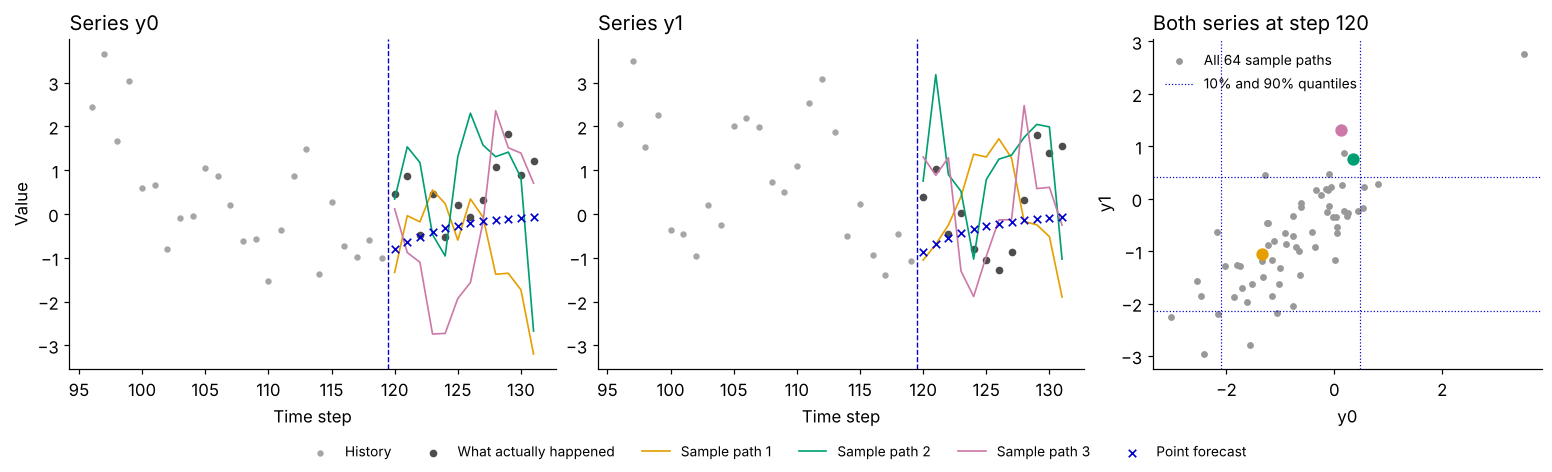

At step 120, the two series are 0.80 correlated across the 64 sample paths.


In [15]:
perfect = case.reference.forecast(n_samples=64, seed=20)
assert perfect.validate(task) == []  # the answer key's own forecast passes the checks
display(pd.DataFrame({'Shape': [perfect.point.shape, perfect.quantiles.shape, perfect.samples.shape],
                      'Axes': ['dates, series', 'dates, series, levels', 'paths, dates, series']},
                     index=['point', 'quantiles', 'samples']))

PATH_COLORS = ['#E69F00', '#009E73', '#CC79A7']
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), width_ratios=[1, 1, .8], layout='constrained')
axes[1].sharey(axes[0])
for target, (ax, name) in enumerate(zip(axes, task.target_names)):
    recent = history.iloc[-24:, target]
    ax.scatter(recent.index, recent, s=10, color='0.65', label='History')
    ax.scatter(case.observed.index, case.observed.iloc[:, target], s=16, color='0.3',
               label='What actually happened')
    for path, color in enumerate(PATH_COLORS):
        ax.plot(dates, perfect.samples[path, :, target], color=color, lw=1.1, label=f'Sample path {path + 1}')
    ax.scatter(dates, perfect.point[:, target], marker='x', s=24, linewidths=1.1, color=BLUE,
               label='Point forecast', zorder=4)
    ax.axvline(dates[0] - 0.5, color=BLUE, ls='--', lw=0.9)
    ax.set(title=f'Series {name}', xlabel='Time step')
axes[0].set_ylabel('Value')

first = perfect.samples[:, 0, :]  # every path's values at the first date to forecast
low, high = perfect.quantiles[0, :, 0], perfect.quantiles[0, :, -1]
ax = axes[2]
ax.scatter(first[:, 0], first[:, 1], s=12, color='0.6', label='All 64 sample paths')
for path, color in enumerate(PATH_COLORS):
    ax.scatter(*first[path], s=50, color=color, zorder=3)
ax.axvline(low[0], color=BLUE, lw=0.8, ls=':', label='10% and 90% quantiles')
ax.axvline(high[0], color=BLUE, lw=0.8, ls=':')
ax.axhline(low[1], color=BLUE, lw=0.8, ls=':')
ax.axhline(high[1], color=BLUE, lw=0.8, ls=':')
ax.set(title=f'Both series at step {dates[0]}', xlabel='y0', ylabel='y1')
ax.legend(loc='upper left', fontsize=9)
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=6, fontsize=9)
plt.show()

link = np.corrcoef(first.T)[0, 1]
assert abs(link) > .5  # the sample paths keep the link between the series
print(f'At step {dates[0]}, the two series are {link:.2f} correlated across the 64 sample paths.')

The blue crosses, the point forecast, fade from each series' last value toward 0. The colored lines are three of the 64 sample paths, and matching colors are the same path: the orange path starts low in both series, the green and pink ones high in both. The right panel shows why that matters. At step 120 the 64 paths form a tilted cloud, 0.80 correlated, because the two series' shocks are linked. The quantiles only mark each series' own range (the dotted lines), and the same lines would fit a round cloud just as well. Only sample paths keep the pairing, so only they can test it ([Multivariate uncertainty](22_multivariate_uncertainty.ipynb)).

## An answer key from a curve you know

Sometimes you know the truth from outside the data: a smooth curve you chose, with noise you add yourself. `Reference.from_function` reads the curve at the dates to forecast and needs the noise's covariance too, because a curve alone says where a series should be, not how far it may stray. Here the curve is the line 2 + 0.1 × step, and the noise is independent with a standard deviation of 0.5 (variance 0.25):

In [16]:
def known_curve(index):
    # What we know about this series: a straight line, 2 plus 0.1 per step.
    return (2.0 + 0.1 * index.to_numpy(dtype=float))[:, None]


when = pd.RangeIndex(20, 24, name='Time step')
supplied = Reference.from_function(known_curve, when, covariance=0.25 * np.eye(len(when)),
                                   conditioning={'truth': '2 + 0.1 * t', 'noise': 'independent Gaussian, sd 0.5'})
np.testing.assert_allclose(supplied.mean[:, 0], [4.0, 4.1, 4.2, 4.3])  # the curve, read at the dates to forecast
low, high = supplied.quantile((.1, .9))[:, 0].T
pd.DataFrame({'Answer key': supplied.mean[:, 0], 'Variance': supplied.variance[:, 0],
              '10% quantile': low, '90% quantile': high}, index=when).round(2)

,Answer key,Variance,10% quantile,90% quantile
Time step,,,,
20,4.0,0.25,3.36,4.64
21,4.1,0.25,3.46,4.74
22,4.2,0.25,3.56,4.84
23,4.3,0.25,3.66,4.94


The answer key is the curve read at each date, and the covariance sets its range: with a standard deviation of 0.5, the 10% and 90% quantiles sit 0.64 below and above the curve. `from_function` calls the curve once and doesn't keep it, so describe the curve in words in `conditioning`, as above. [Write and test a custom model](28_custom_model.ipynb) uses it to give real data an answer key: it smooths monthly airline passengers, declares the smooth curve the truth and adds fresh noise. For real data with no known truth, build the case with `reference=None`, and it is scored against what actually happened only ([Real-data forecasts](24_real_data_forecasts.ipynb)).

**Limits.** The output checks read labels and shapes, not meaning: a forecast whose numbers are swapped but labeled in the task's order passes, and so does a flat line at zero. The quantile check looks at order only; whether the ranges are the right width is scored in [09 · Scores and diagnostics](09_scores_and_diagnostics.ipynb). A Gaussian answer key's quantiles are exact only when the futures really are Gaussian; for jumps and regimes, `SimulationReference` estimates them from simulated paths.

## Change one thing

- Drop `target_names=('y1', 'y0')` from the wrong-order forecast. Its row disappears and the assert in that cell stops you: None means the task's series in order, so the swapped numbers now pass under the wrong names. The checks read labels, not values.
- Move the late forecast by `dates + 3`, or `dates - 1`. The scorecard's description becomes "shifted 3 steps late", or "shifted 1 step early".
- Set `correlation` to -0.8 in the recipe. The cloud tilts the other way, while each series' own range stays as wide.

**Next:** [09 · Scores and diagnostics](09_scores_and_diagnostics.ipynb) scores the forecasts that pass these checks. [Faults, repairs and replay](23_faults_repairs_and_replay.ipynb) breaks correct forecasts on purpose and shows the checks catching them.